# Mall sub-frames (crops)

`make_crops.py` cuts every Mall frame into a grid of tiles (default 3×3 = 9 views of 213×160 px, the WISP 4:3 aspect) and labels each tile using the head points:

| label | meaning |
|---|---|
| **1** person | at least one head point inside the tile |
| **0** empty | no estimated person box (`semwisp.mall.person_boxes`, generous size from the perspective) reaches into the tile, and at most 5% of the tile is outside the annotated ROI |
| **-1** ambiguous | no head inside, but a body probably reaches in from a neighbouring tile, or the tile covers an unannotated area (top-left and top-right shop fronts) |

Use only 0 and 1 for training and evaluation. The -1 crops are useful to look at: they are where head-point labels would mislabel visible bodies as "empty".

Regenerate (resumable) from the repo root: `.venv/Scripts/python.exe data/mall_dataset/cropped/make_crops.py --grid 3x3`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../../..').resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from semwisp.mall import frame_path, load_gt, load_roi

GRID = '3x3'
df = pd.read_csv(f'labels_{GRID}.csv')
points, counts = load_gt()
roi, _ = load_roi()
NAMES = {1: 'person', 0: 'empty', -1: 'ambiguous'}
COLORS = {1: 'tab:red', 0: 'tab:green', -1: 'tab:orange'}
print(f'{len(df)} crops from {df.frame.nunique()} frames, {df.groupby("frame").size().iloc[0]} per frame')
print(df.label.map(NAMES).value_counts().to_string())

18000 crops from 2000 frames, 9 per frame
label
person       14716
ambiguous     2017
empty         1267


## Label balance per tile

Fraction of frames in which each tile is empty / person / ambiguous. The top row is never empty: the far end of the walkway is always busy, and the two top corners are mostly outside the ROI. The empties come from the lower-right tile (the area in front of the right-hand shops) and to a lesser degree from the left and bottom edges.

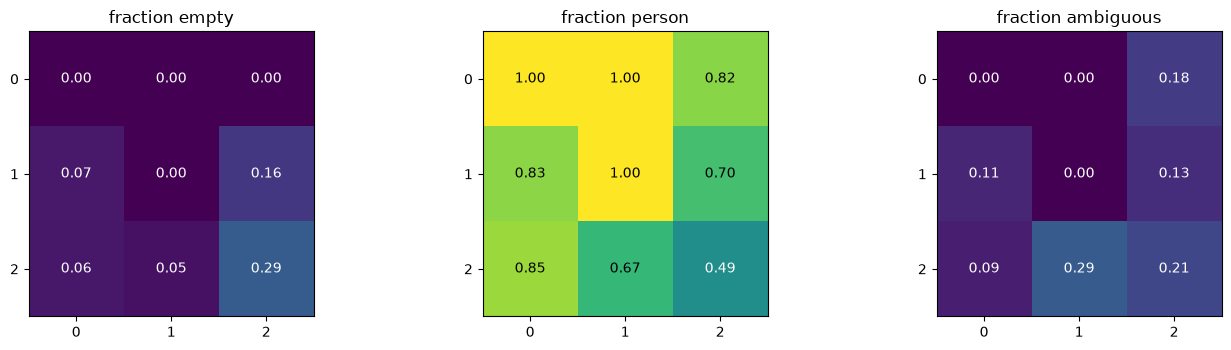

label    ambiguous  empty  person
n_heads                          
0             2017   1267       0
1                0      0    2617
2                0      0    2826
3                0      0    1791
4                0      0    1513
5                0      0    1397
6                0      0    1343
7                0      0    1237
8+               0      0    1992


In [2]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, lab in zip(axs, [0, 1, -1]):
    t = df.assign(v=df.label == lab).pivot_table(index='row', columns='col', values='v', aggfunc='mean')
    ax.imshow(t, cmap='viridis', vmin=0, vmax=1)
    for (r, cc), v in np.ndenumerate(t.values):
        ax.text(cc, r, f'{v:.2f}', ha='center', va='center', color='w' if v < 0.6 else 'k')
    ax.set_title(f'fraction {NAMES[lab]}'); ax.set_xticks(range(t.shape[1])); ax.set_yticks(range(t.shape[0]))
plt.tight_layout(); plt.show()
print(pd.crosstab(df.n_heads.clip(upper=8), df.label.map(NAMES)).rename(index={8: '8+'}))

## A frame with its tile labels

Tiles are outlined in the label colour (red person, green empty, orange ambiguous), with head points and the estimated person boxes. Change `i` to browse.

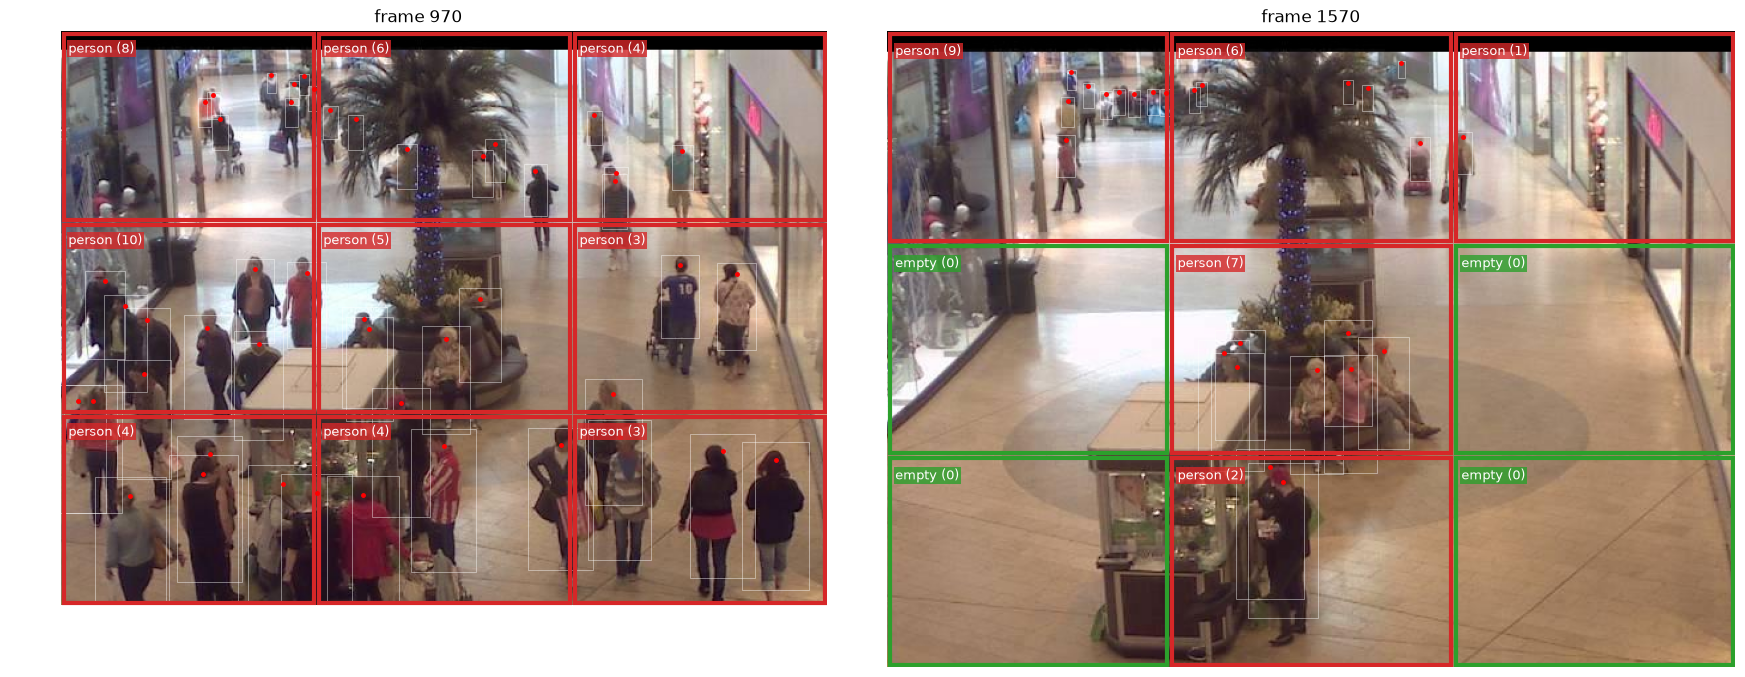

In [3]:
def show_frame(i, ax=None):
    ax = ax or plt.subplots(figsize=(9, 6.75))[1]
    ax.imshow(Image.open(frame_path(i)))
    from semwisp.mall import person_boxes
    for x0, y0, x1, y1 in person_boxes(points[i - 1]):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='w', lw=0.5, alpha=0.6))
    ax.plot(points[i - 1][:, 0], points[i - 1][:, 1], 'r.', ms=5)
    for _, t in df[df.frame == i].iterrows():
        ax.add_patch(Rectangle((t.x0 + 2, t.y0 + 2), t.x1 - t.x0 - 4, t.y1 - t.y0 - 4, fill=False, ec=COLORS[t.label], lw=3))
        ax.text(t.x0 + 6, t.y0 + 18, f'{NAMES[t.label]} ({t.n_heads})', color='w', fontsize=9,
                bbox=dict(fc=COLORS[t.label], ec='none', alpha=0.8, pad=1))
    ax.set_title(f'frame {i}'); ax.axis('off')

frames_with_empty = df[df.label == 0].groupby('frame').size().sort_values(ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(18, 6.75))
show_frame(970, axs[0]); show_frame(int(frames_with_empty.index[0]), axs[1])
plt.tight_layout(); plt.show()

## Random crops per label

Native-resolution crops, picked at random. Most empty crops are bare floor, shop fronts or the kiosk, but the labels are not perfect. In this sample, f336 r2c2 shows the legs of a small unannotated child, and the dark shape by the kiosk in f52 r2c1 may be a person. The ambiguous crops are mostly legs and lower bodies of people whose heads are in the tile above, plus the unannotated top-right shop front with its mannequins. For a presence detector, the legs-only crops are arguably positives.

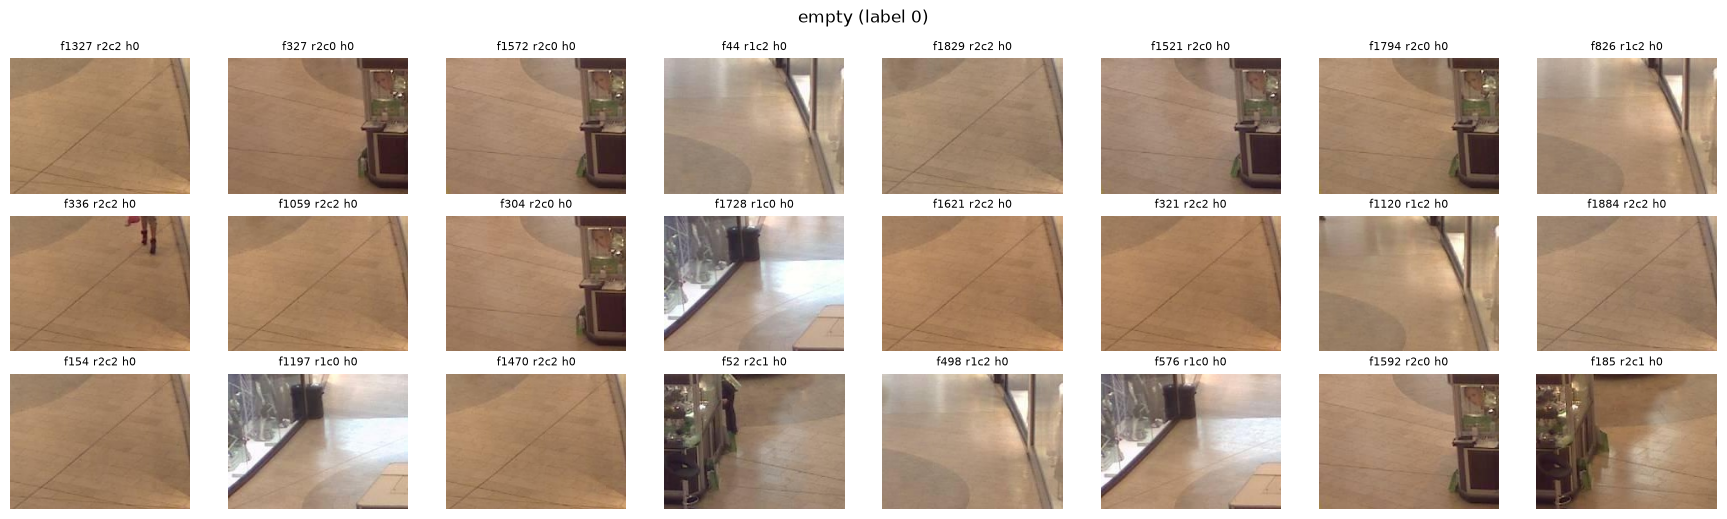

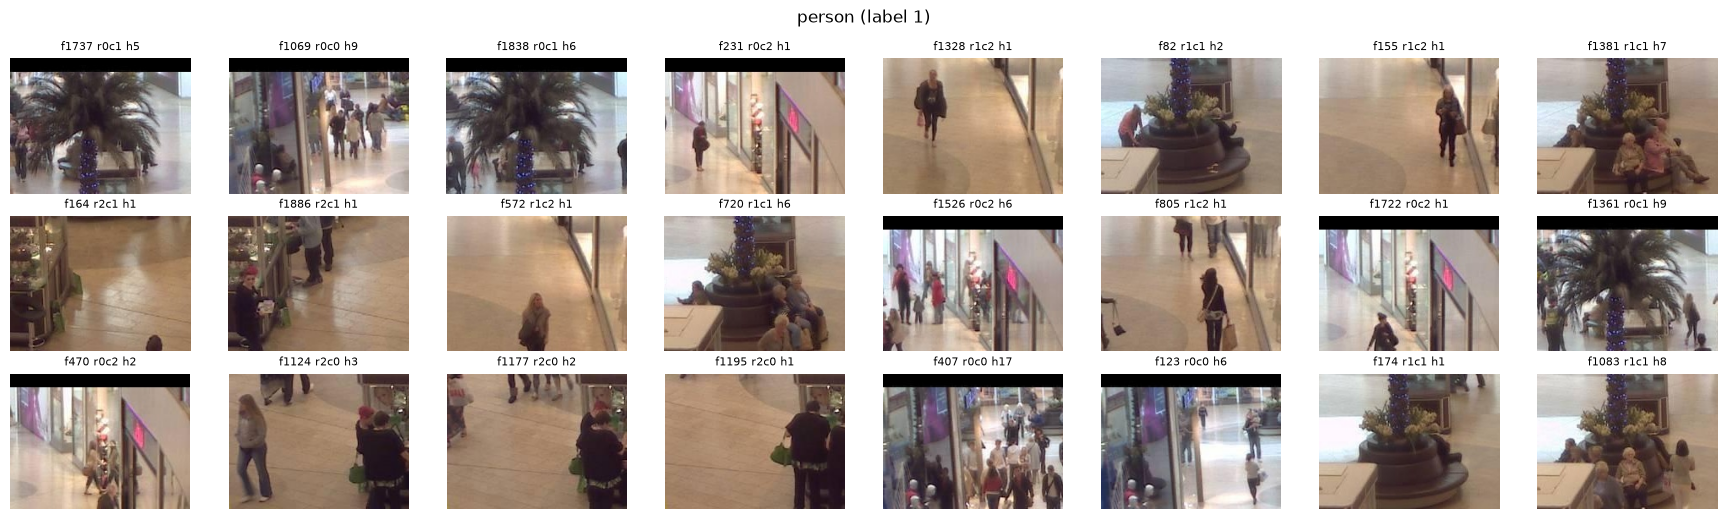

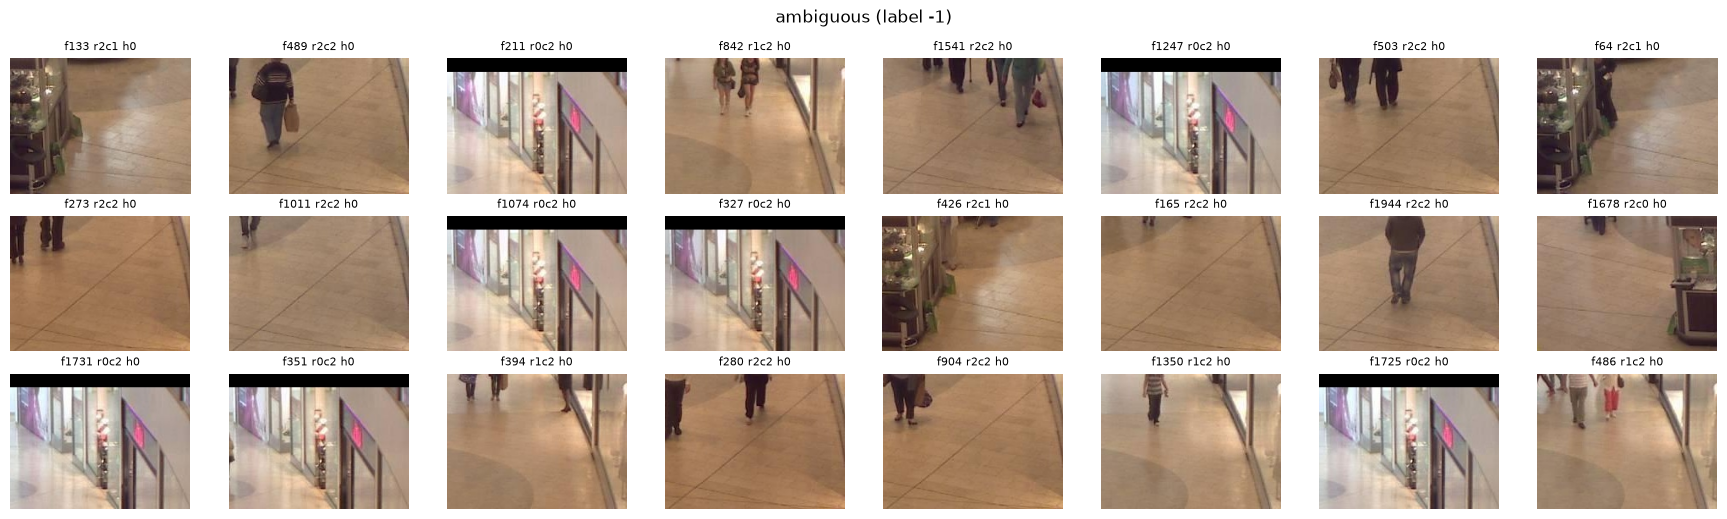

In [4]:
def crop_grid(sub, n=24, cols=8, seed=0, title=''):
    sub = sub.sample(min(n, len(sub)), random_state=seed)
    rows = int(np.ceil(len(sub) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(2.2 * cols, 1.75 * rows))
    for ax in np.ravel(axs): ax.axis('off')
    for ax, (_, t) in zip(np.ravel(axs), sub.iterrows()):
        ax.imshow(Image.open(t.file))
        ax.set_title(f'f{t.frame} r{t.row}c{t.col} h{t.n_heads}', fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

for lab in [0, 1, -1]:
    crop_grid(df[df.label == lab], title=f'{NAMES[lab]} (label {lab})')

## At WISP resolution

The same kind of crops after a bilinear resize to 160×120 grayscale (the WISP input), as the tag would see them if the camera were pointed at that part of the mall.

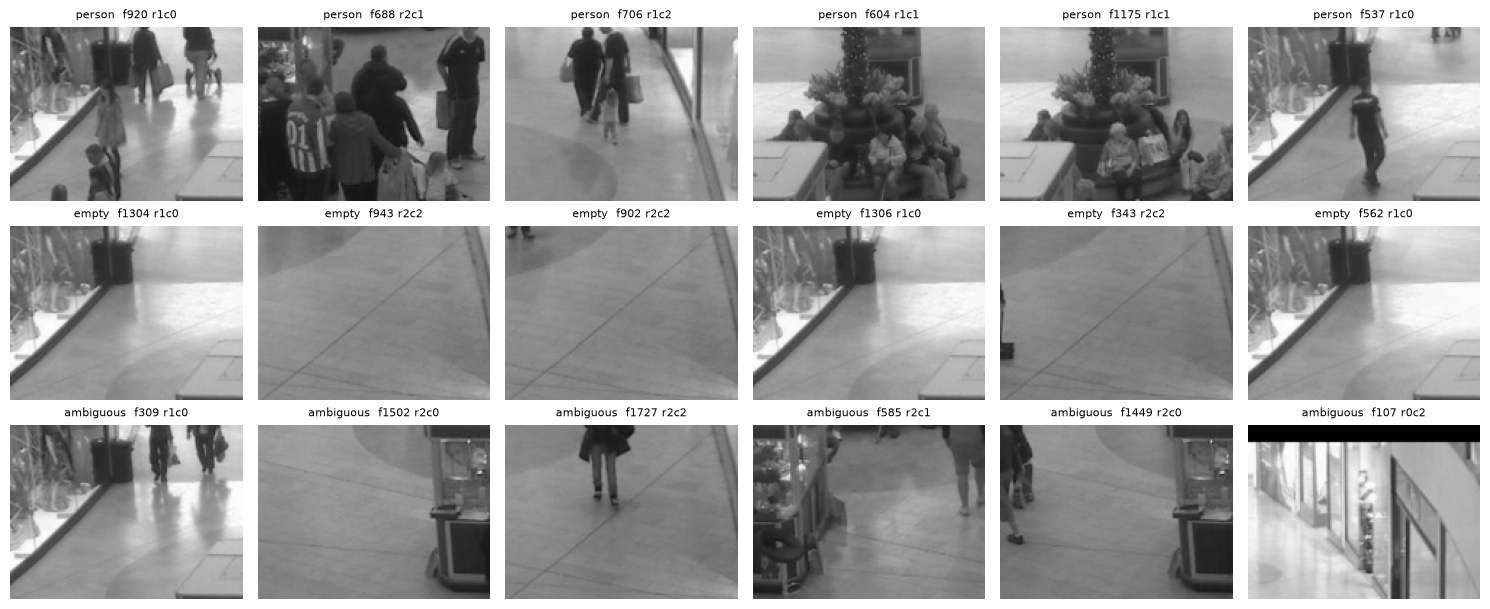

In [5]:
from semwisp.piropo import load_gray
sub = pd.concat([df[df.label == lab].sample(6, random_state=1) for lab in [1, 0, -1]])
fig, axs = plt.subplots(3, 6, figsize=(15, 6.2))
for ax, (_, t) in zip(axs.ravel(), sub.iterrows()):
    ax.imshow(load_gray(t.file), cmap='gray', vmin=0, vmax=255); ax.axis('off')
    ax.set_title(f'{NAMES[t.label]}  f{t.frame} r{t.row}c{t.col}', fontsize=8)
plt.tight_layout(); plt.show()

## Empty crops over time

Each tile is a fixed view, like a fixed WISP camera. Below: when each tile is empty (green), has a person (red) or is ambiguous (orange), frame by frame. Empty spells are short (median 2-4 frames, longest 25), and some tiles are almost never empty (r1c1, the planter). Still split train and test by contiguous frame blocks, and report per-tile results, because each tile has its own background and base rate.

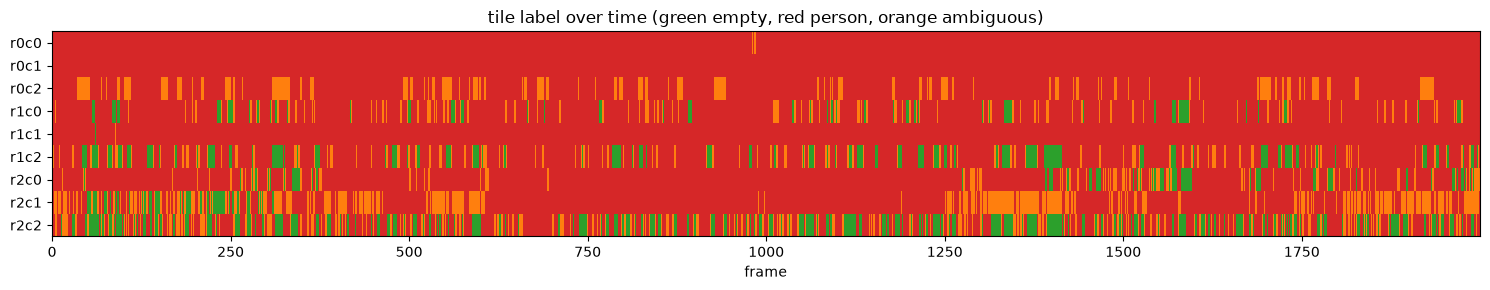

tile  empty  runs  median_run  longest
r1c0    137    47         2.0       13
r1c1      1     1         1.0        1
r1c2    327    66         4.0       25
r2c0    126    47         2.0       15
r2c1     91    26         2.0       16
r2c2    585   164         2.0       21


In [5]:
tiles = df[['row', 'col']].drop_duplicates().sort_values(['row', 'col']).values
M = np.stack([df[(df.row == r) & (df.col == cc)].sort_values('frame').label.values for r, cc in tiles])
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(15, 3))
ax.imshow(M + 1, aspect='auto', interpolation='nearest', cmap=ListedColormap([COLORS[-1], COLORS[0], COLORS[1]]), vmin=0, vmax=2)
ax.set_yticks(range(len(tiles))); ax.set_yticklabels([f'r{r}c{cc}' for r, cc in tiles]); ax.set_xlabel('frame')
ax.set_title('tile label over time (green empty, red person, orange ambiguous)')
plt.tight_layout(); plt.show()

runs = []
for r, cc in tiles:
    e = (df[(df.row == r) & (df.col == cc)].sort_values('frame').label.values == 0).astype(int)
    edges = np.diff(np.r_[0, e, 0]); lens = np.where(edges == -1)[0] - np.where(edges == 1)[0]
    if len(lens): runs.append(dict(tile=f'r{r}c{cc}', empty=e.sum(), runs=len(lens), median_run=np.median(lens), longest=lens.max()))
print(pd.DataFrame(runs).to_string(index=False))

## Summary

- The 3×3 grid gives 18,000 crops: 14,716 person, 1,267 empty (7%), 2,017 ambiguous. The Mall is crowded, so empties are rare even per tile. They come mostly from the lower-right tile (29% of frames) and the left and bottom edges (5–16%); the top row is never empty.
- Head points inside a tile do not mean a whole person: a tile can hold only a head, or only legs (ambiguous). For presence detection that is still a "person" view, which is why ambiguous crops are kept out of the empty class rather than added to it.
- If more negatives are needed, finer grids help: on the same rules, 4×3 gives 2,070 empty / 4,161 ambiguous out of 24,000, and 4×4 (160×120 tiles, exactly the WISP resolution with no resize) gives 3,466 empty / 6,876 ambiguous out of 32,000. Run `make_crops.py --grid 4x4`.
- The empty/person boundary depends on `semwisp.mall.person_height`, a hand-fitted size model. Spot checks show a few unannotated people (for example small children) inside empty crops, so treat the empty labels as slightly noisy, as with PIROPO. Legs-only ambiguous crops could reasonably be relabelled as person.